In [1]:
import numpy as np
import cupy as cp
import matplotlib.pyplot as plt
import math

from itertools import combinations 

import seaborn as sns 

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 12,
    "font.size": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

In [2]:
def compute_r_index(N, N_iterazioni, hamil):
    
    energies = cp.empty((N_iterazioni, hamil.shape[1]), dtype=cp.float64)
        
    for i in range(N_iterazioni):
        energies[i] = cp.linalg.eigvalsh(hamil[i])

    lenght = energies.shape[1]
    trim = int(lenght*0.1)
    bulk_energies = energies[:, trim : -trim]

    new_spacing = cp.diff(bulk_energies, axis=1)

    mask = cp.abs(new_spacing) > 1e-10
    new_spacing = new_spacing[mask].reshape(new_spacing.shape[0], -1)
    
    r_matrix = new_spacing[:, 1:] / new_spacing[:, :-1]     
    
    r_index_matrix = cp.minimum(r_matrix, 1/r_matrix)
    r_index_mean = cp.mean(r_index_matrix, axis=1)
    
    r_index_est = cp.mean(r_index_mean)
    sigma_index_est = cp.std(r_index_mean)/cp.sqrt(len(r_index_mean))

    return r_index_est, sigma_index_est, r_matrix, r_index_matrix


## Algebra representation

In [11]:
N = 8
Gammas = []
Gammas_bar = []
sigma_plus = cp.sqrt(2)*cp.array(([0,1],[0,0]), dtype=float)
sigma_minus = cp.sqrt(2)*cp.array(([0,0],[1,0]), dtype=float)

id = cp.eye(2**(N-1))
newgamma = cp.kron(id, sigma_plus)
Gammas.append(newgamma)

newgamma = cp.kron(id, sigma_minus)
Gammas_bar.append(newgamma)

diag = cp.empty(2**N, dtype=cp.int8)
diag[0] = 1

for i in range(N-1):
    lenght = 2**i
    diag[lenght : 2*lenght] = - diag[:lenght]

    sigma_3 = cp.diag(diag[:2*lenght])

    id = cp.eye(2**(N-i-2))

    newgamma = cp.kron(sigma_plus, sigma_3)
    newgamma = cp.kron(id, newgamma)
    Gammas.append(newgamma)

    newgamma = cp.kron(sigma_minus, sigma_3)
    newgamma = cp.kron(id, newgamma)
    Gammas_bar.append(newgamma)

Gammas.reverse()
Gammas_bar.reverse()

Gamma_tensor = cp.stack(Gammas)
Gamma_bar_tensor = cp.stack(Gammas_bar)

## Hamiltonian construction

In [5]:
p = 3
J = 1.0
N_iterazioni = 1000
M = math.comb(N,p)

sigma_J = J**2 * M**(-2)

A = cp.random.normal(loc = 0.0, scale = sigma_J, size = (N_iterazioni, M, M))
B = cp.random.normal(loc = 0.0, scale = sigma_J, size = (N_iterazioni, M, M))

re_couplings = (A + cp.transpose(A, (0,2,1))) * 0.5
im_couplings = (B - cp.transpose(B, (0,2,1))) * 0.5

couplings = re_couplings + 1j*im_couplings

idx = cp.asarray(list(combinations(range(N), p)))
mono = Gamma_tensor[idx[:, 0]]
mono_bar = Gamma_bar_tensor[idx[:, p-1]]
for i in range(p-1):
    mono = mono @ Gamma_tensor[idx[:, i+1]]

    mono_bar = mono_bar @ Gamma_bar_tensor[idx[:, p-i-2]]

tetra = cp.einsum('ijk,lkm->iljm', mono_bar, mono)


In [6]:
Q = cp.einsum('ijk,ikl->jl', Gamma_bar_tensor, Gamma_tensor)
Q *= 0.5
Q = cp.round(Q).astype(cp.int64)

diag = Q.diagonal()

blocks = []

for i in range(N+1-2*p):
    mask = cp.where(diag == i+p)[0]
    new_block = tetra[:,:, mask,:][:,:,:,mask]
    blocks.append(new_block)


In [7]:
hamil = []

list_comb = list(combinations(range(N), p))
list_set = [set(c) for c in list_comb]

for idx_l, set_l in enumerate(list_set):
    for idx_c, set_c in enumerate(list_set):
        if not set_l.isdisjoint(set_c):
            couplings[:, idx_l, idx_c] = 0

for i in range(len(blocks)):
    new_hamil_stack = cp.einsum('kij,jilm->klm', couplings, blocks[i])
    hamil.append(new_hamil_stack)


## Spectrum analysis

In [ ]:
r = []
r_index = []

r_index_est = cp.zeros(len(hamil), dtype = cp.float32)
sigma_index_est = cp.zeros(len(hamil), dtype = cp.float32)
stat = cp.zeros(len(hamil), dtype=cp.int64)

for i in range(len(hamil)):
    r_index_est[i], sigma_index_est[i], r_matrix, r_index_matrix = compute_r_index(N, N_iterazioni, hamil[i])

    r_new = r_matrix.flatten()
    r_index_new = r_index_matrix.flatten()

    stat[i] = r_new.shape[0]

    r_new = r_new.get()
    r_index_new = r_index_new.get()

    r.append(r_new)
    r_index.append(r_new)


3
2
1


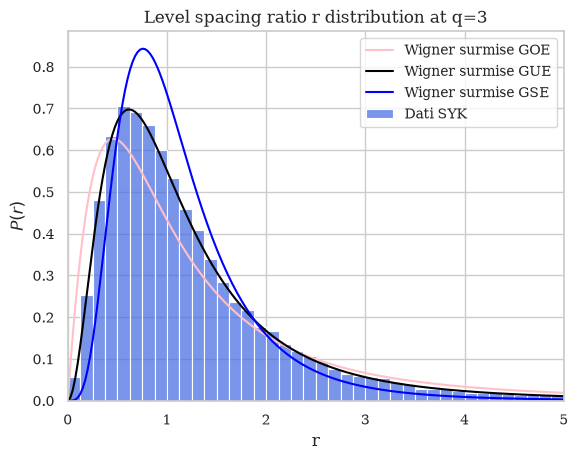

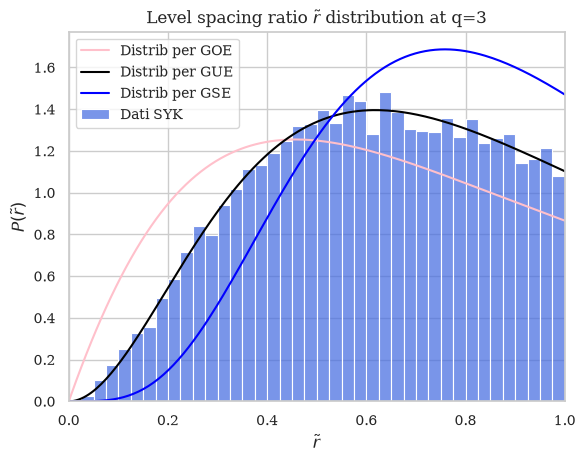

r-tilde = 0.6017971038818359 +- 0.0014132389333099127
Statistics = 44000


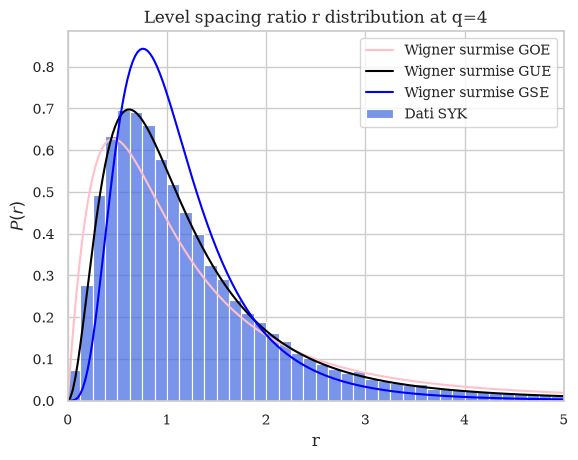

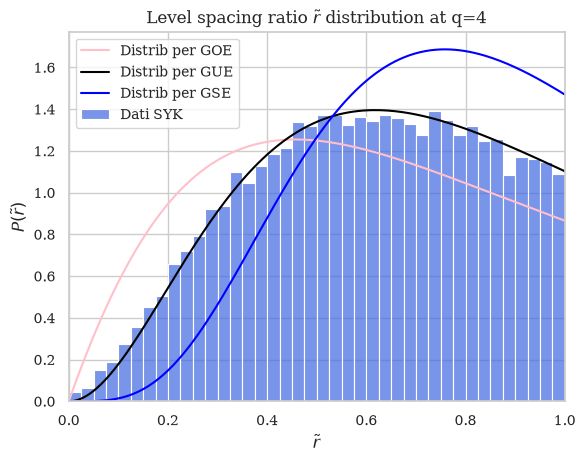

r-tilde = 0.5948866605758667 +- 0.0017810834106057882
Statistics = 54000


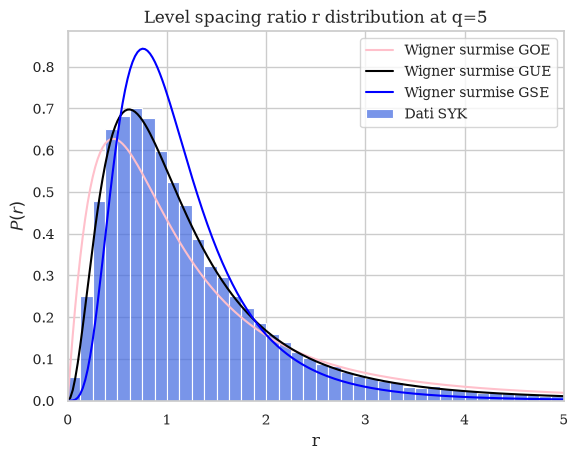

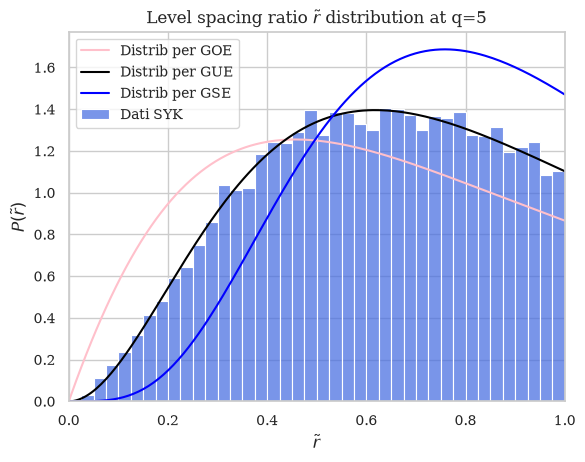

r-tilde = 0.6017971038818359 +- 0.0014132389333099127
Statistics = 44000


In [12]:
N_bin = 40

for i in range(len(r)):

    sns.histplot(r[i], bins=N_bin, binrange=(0,5), stat="density",
                color='royalblue', alpha=0.7, label='Dati SYK')

    r_asse = np.linspace(0, 5, 200)
    P_goe = (27/8)*(r_asse + r_asse**2)/(1 + r_asse + r_asse**2)**(2.5)
    plt.plot(r_asse, P_goe, color='pink', linewidth=1.5, label='Wigner surmise GOE')

    P_gue = (81/4) * (np.sqrt(3)/np.pi) * (r_asse + r_asse**2)**2/(1 + r_asse + r_asse**2)**(4)
    plt.plot(r_asse, P_gue, color='black', linewidth=1.5, label='Wigner surmise GUE')

    P_gse = (729/4) * (np.sqrt(3)/np.pi) * (r_asse + r_asse**2)**4/(1 + r_asse + r_asse**2)**(7)
    plt.plot(r_asse, P_gse, color='blue', linewidth=1.5, label='Wigner surmise GSE')

    # P_poisson = 1/(1+r_asse)**2
    # plt.plot(r_asse, P_poisson, color='blue', linewidth=1.5, label='Distrib from Poisson')


    plt.xlabel(r'r')
    plt.ylabel(fr'$P(r)$')
    plt.title(fr'Level spacing ratio r distribution at q={i+p}')
    plt.xlim(0, 5)
    plt.legend()
    plt.show()

    r_index_asse = np.linspace(0, 1, 200)
    P_index_goe = (27/4)*(r_index_asse + r_index_asse**2)/(1 + r_index_asse + r_index_asse**2)**(2.5)
    plt.plot(r_index_asse, P_index_goe, color='pink', linewidth=1.5, label='Distrib per GOE')

    P_index_gue = 2*(81/4) * (np.sqrt(3)/np.pi) * (r_index_asse + r_index_asse**2)**2/(1 + r_index_asse + r_index_asse**2)**(4)
    plt.plot(r_index_asse, P_index_gue, color='black', linewidth=1.5, label='Distrib per GUE')

    P_index_gse = 2*(729/4) * (np.sqrt(3)/np.pi) * (r_index_asse + r_index_asse**2)**4/(1 + r_index_asse + r_index_asse**2)**(7)
    plt.plot(r_index_asse, P_index_gse, color='blue', linewidth=1.5, label='Distrib per GSE')

    # P_index_poisson = 2/(1+r_index_asse)**2
    # plt.plot(r_index_asse, P_index_poisson, color='blue', linewidth=1.5, label='Distrib from Poisson')


    sns.histplot(r_index[i], bins=N_bin, binrange=(0, 1), stat="density",
                color='royalblue', alpha=0.7, label='Dati SYK')

    plt.xlabel(fr'$\tilde r$')
    plt.ylabel(fr'$P(\tilde r)$')
    plt.title(fr'Level spacing ratio $\tilde r$ distribution at q={i+p}')
    plt.xlim(0, 1)
    plt.legend()
    plt.show()

    print(fr'r-tilde = {r_index_est[i]} +- {sigma_index_est[i]}')
    print(fr'Statistics = {stat[i]}')

